# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Dylan Wang, Lani Le, Yipeng Cao

**Date:** 11/16/2026

In [1]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from scipy.stats import pearsonr

In [14]:
# 1. Check out the data set `heart_failure` and appropriately clean it.
df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')

# inspect the data
display(df.head())
print(df.shape)
print(df.info())
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

# remove duplicate rows and rows with missing values
df = df.drop_duplicates().dropna().copy()

target = "DEATH_EVENT"
X = df.drop(columns=target)
y = df[target]

print("Cleaned shape:", df.shape)
print("Target values:", sorted(y.unique()))

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


(299, 13)
<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB
None
age           

The dataset contained 299 rows and 13 columns. There were no missing values or duplicate rows, so cleaning did not remove any observations. I used the 12 clinical measurements as predictors and DEATH_EVENT as the outcome.

In [15]:
# 2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

 
BASE_SEED = 20

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=BASE_SEED
)

tree_baseline = DecisionTreeRegressor(random_state=BASE_SEED)
linear_baseline = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

tree_baseline.fit(X_train, y_train)
linear_baseline.fit(X_train, y_train)

tree_pred_baseline = tree_baseline.predict(X_test)
linear_pred_baseline = linear_baseline.predict(X_test)

def report_metrics(name, actual, predicted):
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    print(f"{name}: MSE={mse:.4f}, RMSE={rmse:.4f}, R²={r2:.4f}")

report_metrics("Decision tree", y_test, tree_pred_baseline)
report_metrics("Linear regression", y_test, linear_pred_baseline)




Decision tree: MSE=0.2667, RMSE=0.5164, R²=-0.2864
Linear regression: MSE=0.1507, RMSE=0.3882, R²=0.2729


With seed 20, linear regression performed better than the decision tree on the test set. The linear model had an RMSE of 0.3882 and an R^2 of 0.2729, while the tree had an RMSE of 0.5164 and an R^2 of -0.2864. The negative R^2 means the tree performed worse than simply predicting the test-set average for every observation.

In [16]:
# 3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
from sklearn.tree import export_text

SEEDS = [7, 201, 199, 2026]

tree_models = {}
linear_models = {}
tree_predictions = {}
linear_predictions = {}
split_metrics = []

for seed in SEEDS:
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.25, random_state=seed
    )

    tree = DecisionTreeRegressor(random_state=seed)
    linear = make_pipeline(StandardScaler(), LinearRegression())

    tree.fit(X_train_s, y_train_s)
    linear.fit(X_train_s, y_train_s)

    tree_models[seed] = tree
    linear_models[seed] = linear

    # evaluate on this seed's own test set
    split_metrics.append({
        "seed": seed,
        "tree_R2": r2_score(y_test_s, tree.predict(X_test_s)),
        "linear_R2": r2_score(y_test_s, linear.predict(X_test_s))
    })

    # save predictions on the same test set used in Question 2
    tree_predictions[seed] = tree.predict(X_test)
    linear_predictions[seed] = linear.predict(X_test)

print(pd.DataFrame(split_metrics).set_index("seed"))

# show each tree's rules to see how its structure changes
for seed, tree in tree_models.items():
    print(f"\nDecision tree for seed {seed}:")
    print(export_text(tree, feature_names=list(X.columns), max_depth=4))

coefficient_table = pd.DataFrame(
    {
        seed: model.named_steps["linearregression"].coef_
        for seed, model in linear_models.items()
    },
    index=X.columns
)

display(coefficient_table)


       tree_R2  linear_R2
seed                     
7    -0.096491   0.302833
201  -0.093482   0.269494
199  -0.059655   0.267488
2026 -0.064909   0.324934

Decision tree for seed 7:
|--- time <= 69.00
|   |--- creatinine_phosphokinase <= 80.50
|   |   |--- serum_sodium <= 134.50
|   |   |   |--- value: [1.00]
|   |   |--- serum_sodium >  134.50
|   |   |   |--- value: [0.00]
|   |--- creatinine_phosphokinase >  80.50
|   |   |--- ejection_fraction <= 72.50
|   |   |   |--- creatinine_phosphokinase <= 2018.00
|   |   |   |   |--- creatinine_phosphokinase <= 159.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- creatinine_phosphokinase >  159.50
|   |   |   |   |   |--- value: [1.00]
|   |   |   |--- creatinine_phosphokinase >  2018.00
|   |   |   |   |--- platelets <= 284179.02
|   |   |   |   |   |--- value: [1.00]
|   |   |   |   |--- platelets >  284179.02
|   |   |   |   |   |--- value: [0.00]
|   |   |--- ejection_fraction >  72.50
|   |   |   |--- value

,7,201,199,2026
age,0.079786,0.077525,0.078940,0.082196
anaemia,-0.026211,-0.004689,0.003807,-0.007610
creatinine_phosphokinase,0.002193,0.019973,0.045319,0.036723
diabetes,-0.002544,-0.017043,0.018898,0.012011
ejection_fraction,-0.101002,-0.118066,-0.126644,-0.138226
high_blood_pressure,-0.023108,0.011515,0.004869,-0.016837
platelets,-0.030477,-0.015207,0.002873,-0.011163
serum_creatinine,0.078348,0.096218,0.043927,0.070128
serum_sodium,-0.031904,-0.003622,-0.050939,-0.047068
sex,-0.038447,-0.026758,0.001395,-0.023597


The trees changed across train/test splits: their rules depended on different split points and paths through the data. Their predictions on the baseline test set were also only moderately correlated with the seed-20 tree predictions, with correlations around 0.39–0.46.

The linear coefficients were more stable for some features than others. For example, the age coefficient had a standard deviation of about 0.002 across seeds; the coefficients for time and ejection fraction also stayed similar. Several smaller coefficients changed sign, though their values remained relatively close to zero.

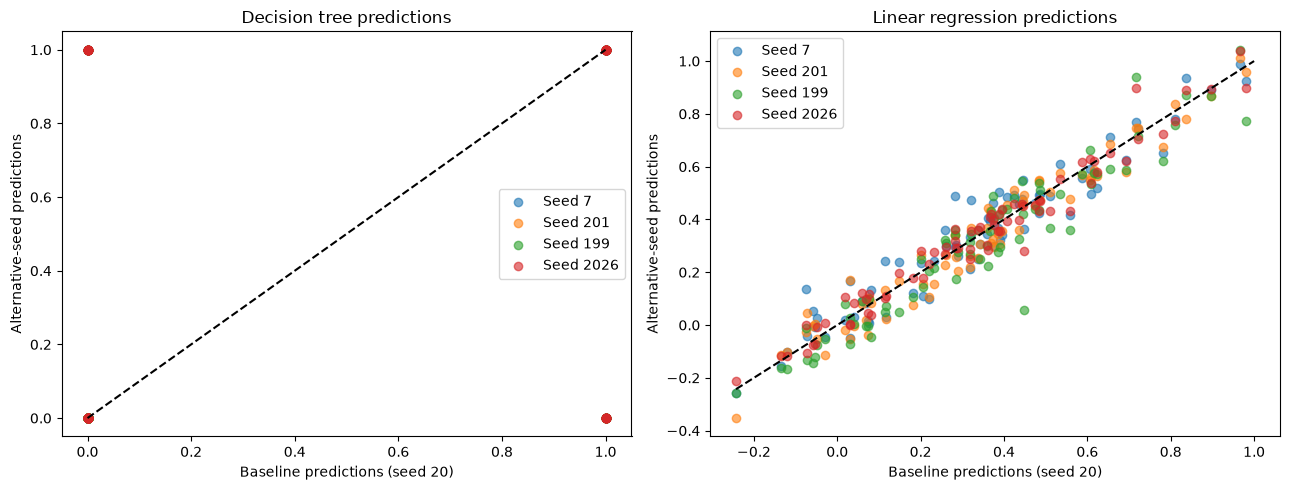

,model,seed,correlation,intercept,slope,R2
0,Tree,7,0.461261,0.163265,0.452119,0.212762
1,Tree,201,0.419314,0.142857,0.395604,0.175824
2,Tree,199,0.426934,0.163265,0.413658,0.182272
3,Tree,2026,0.387563,0.224490,0.390895,0.150205
4,Linear,7,0.961117,0.025502,0.944170,0.923746
5,Linear,201,0.976062,-0.009091,0.986686,0.952697
6,Linear,199,0.953807,-0.025352,0.990184,0.909748
7,Linear,2026,0.981686,0.013207,0.965096,0.963707


In [21]:
# 4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
# But are they? Instead of focusing on the tree or model coefficients, do three things:
    
#     a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for seed in SEEDS:
    axes[0].scatter(
        tree_pred_baseline,
        tree_predictions[seed],
        alpha=0.6,
        label=f"Seed {seed}"
    )
    axes[1].scatter(
        linear_pred_baseline,
        linear_predictions[seed],
        alpha=0.6,
        label=f"Seed {seed}"
    )

# diagonal line indicates identical predictions
for ax, baseline_preds, title in [
    (axes[0], tree_pred_baseline, "Decision tree predictions"),
    (axes[1], linear_pred_baseline, "Linear regression predictions")
]:
    low = min(baseline_preds.min(), 0)
    high = max(baseline_preds.max(), 1)
    ax.plot([low, high], [low, high], "k--")
    ax.set_xlabel("Baseline predictions (seed 20)")
    ax.set_ylabel("Alternative-seed predictions")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

#     b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not
#     c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?
comparison_rows = []

for model_name, baseline_preds, alternatives in [
    ("Tree", tree_pred_baseline, tree_predictions),
    ("Linear", linear_pred_baseline, linear_predictions)
]:
    for seed, alt_preds in alternatives.items():
        # correlation between baseline and alternative predictions
        correlation = np.corrcoef(baseline_preds, alt_preds)[0, 1]

        # regress alternative predictions on baseline predictions
        comparison_model = LinearRegression()
        comparison_model.fit(baseline_preds.reshape(-1, 1), alt_preds)
        alt_from_baseline = comparison_model.predict(
            baseline_preds.reshape(-1, 1)
        )

        comparison_rows.append({
            "model": model_name,
            "seed": seed,
            "correlation": correlation,
            "intercept": comparison_model.intercept_,
            "slope": comparison_model.coef_[0],
            "R2": r2_score(alt_preds, alt_from_baseline)
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)





4a. Prediction scatterplots
The tree scatterplot shows substantial disagreement: many predictions fall away from the diagonal, and the tree predictions are often concentrated at 0 or 1. The linear model’s points cluster much closer to the diagonal, suggesting its predictions are more similar across splits.


4b–c. Correlation and regression comparison
The alternative tree predictions were not highly correlated with the baseline tree predictions: correlations ranged from about 0.39 to 0.46. Their regression slopes were about 0.39–0.45, intercepts about 0.14–0.22, and R^2 values about 0.15–0.21. These results indicate that tree predictions changed considerably across splits.

The linear model predictions were highly correlated with the baseline predictions, with correlations from about 0.95 to 0.98. Its regression intercepts were close to zero, slopes were about 0.94–0.99, and R^2 values were about 0.91–0.96. This indicates that linear predictions were quite similar across splits.

In [19]:
# 5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
print("Linear coefficient spread across seeds:")
display(
    coefficient_table.assign(
        mean=coefficient_table.mean(axis=1),
        std=coefficient_table.std(axis=1)
    ).sort_values("std", ascending=False)
)

# correlation of each seed's predictions with the baseline predictions
prediction_stability = []

for model_name, baseline_preds, alternatives in [
    ("Tree", tree_pred_baseline, tree_predictions),
    ("Linear", linear_pred_baseline, linear_predictions)
]:
    for seed, alt_preds in alternatives.items():
        prediction_stability.append({
            "model": model_name,
            "seed": seed,
            "prediction_correlation_with_baseline":
                np.corrcoef(baseline_preds, alt_preds)[0, 1],
            "mean_absolute_prediction_difference":
                np.mean(np.abs(baseline_preds - alt_preds))
        })

display(pd.DataFrame(prediction_stability))

Linear coefficient spread across seeds:


,7,201,199,2026,mean,std
serum_creatinine,0.078348,0.096218,0.043927,0.070128,0.072155,0.021743
serum_sodium,-0.031904,-0.003622,-0.050939,-0.047068,-0.033383,0.021474
creatinine_phosphokinase,0.002193,0.019973,0.045319,0.036723,0.026052,0.019073
sex,-0.038447,-0.026758,0.001395,-0.023597,-0.021852,0.016762
high_blood_pressure,-0.023108,0.011515,0.004869,-0.016837,-0.005890,0.016683
diabetes,-0.002544,-0.017043,0.018898,0.012011,0.002831,0.015982
ejection_fraction,-0.101002,-0.118066,-0.126644,-0.138226,-0.120985,0.015675
time,-0.231445,-0.219472,-0.216727,-0.197298,-0.216235,0.014150
platelets,-0.030477,-0.015207,0.002873,-0.011163,-0.013493,0.013719
anaemia,-0.026211,-0.004689,0.003807,-0.007610,-0.008676,0.012654


,model,seed,prediction_correlation_with_baseline,mean_absolute_prediction_difference
0,Tree,7,0.461261,0.240000
1,Tree,201,0.419314,0.253333
2,Tree,199,0.426934,0.253333
3,Tree,2026,0.387563,0.280000
4,Linear,7,0.961117,0.060457
5,Linear,201,0.976062,0.053074
6,Linear,199,0.953807,0.067929
7,Linear,2026,0.981686,0.039682


The linear model’s most prominent coefficients were fairly consistent, and its predictions were stable across splits. Some smaller coefficients changed sign. The trees’ rules and predictions were less stable: their average prediction correlation with the baseline tree was about 0.42, with an average absolute prediction difference of about 0.26.

In [20]:
# 6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."
stability_df = pd.DataFrame(prediction_stability)

print("Average prediction correlation with baseline:")
display(stability_df.groupby("model")[
    "prediction_correlation_with_baseline"
].mean())

print("\nAverage absolute prediction difference from baseline:")
display(stability_df.groupby("model")[
    "mean_absolute_prediction_difference"
].mean())

Average prediction correlation with baseline:


model
Linear    0.968168
Tree      0.423768
Name: prediction_correlation_with_baseline, dtype: float64


Average absolute prediction difference from baseline:


model
Linear    0.055286
Tree      0.256667
Name: mean_absolute_prediction_difference, dtype: float64

False. The linear models’ predictions were similar across splits, even when their coefficients shifted somewhat. But the tree predictions were not very similar across splits, despite being the same type of model. So the claim fits the linear models here, but not the trees.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** f654173cbfe18809a88e364fd773627059622595
- **AI tool and model used:** GPT 6

### *Prompts used

1. "Scan through my code in phase 1 and see if they addressed the questions that were asked, give detailed implementation and modification plans along with the code that can improve or correct current phase 1"

No follow-up prompt was used.

### *AI-proposed changes


1. Explicitly review coverage of Questions 1–6 and the limits of its conclusions.
2. Reserve one common holdout before fitting any models, then vary equal-sized training subsets within the remaining data using the saved baseline seed and four alternative seeds.
3. Retain the regression models for the lab, explain the binary-outcome and follow-up-time limitations, and report both internal-test and common-holdout MSE, RMSE, and R².
4. Compare baseline and alternative tree structures and linear coefficients in original feature units, including intercepts.
5. Save row-aligned predictions, plot each baseline–alternative pair, and report correlations, comparison-regression intercepts/slopes/R², and absolute prediction differences.
6. Rewrite the answers to Questions 5–6 using the corrected results, and verify the holdout separation and numerical comparisons.

### *Evaluation of AI suggestions



| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Phase 1 covers all six questions and its numerical interpretations agree with its saved outputs. It does not establish fully out-of-sample stability because alternative training sets overlap the baseline test set. Phase 1 cells remain unchanged. |
| 2 | Accept | All five models now use equal training sizes and predict the same never-trained-on patients. Assertions check index separation and alignment. The smaller training samples mean these numerical results need not match Phase 1. |
| 3 | Modify | Retain ordinary least squares and a regression tree to match Phase 1 and the lab's regression comparisons. A binary target makes this a linear probability analysis; predictions need not lie in [0, 1]. Retain `time` for comparability, but acknowledge that follow-up duration is unavailable at an initial visit, so this is not a baseline clinical prediction model. |
| 4 | Accept | Undo each fitted scaler before comparing coefficients. Include the baseline, intercepts, tree depth, leaf count, root splits, and printed rules. Coefficients in original units are comparable across splits but not directly comparable in magnitude across different features. |
| 5 | Accept | Patient-indexed tables and one panel per alternative make the comparison traceable. Regression direction is alternative prediction on baseline prediction; assertions verify that its R² equals squared correlation. Tree marker sizes expose overlapping binary points. |
| 6 | Accept | Generate the final numerical interpretations from the executed tables. Similarity is model-specific, and stability alone does not establish predictive accuracy. |


### *AI-assisted solution in full

#### Review of Phase 1

**Q1:** Inspection and cleaning are complete: 299 rows, no missing values, and no duplicates. One description needs qualification: `time` is follow-up duration, not an initial clinical measurement (see the supplied data readme).

**Q2:** The saved seed, fitted models, predictions, and test metrics satisfy the question. Regression on a binary outcome is acceptable for this lab's numerical comparison, but OLS outputs are not guaranteed probabilities.

**Q3:** Four alternative seeds, test evaluations, tree rules, and coefficient tables are present. The baseline coefficients should also be included. Separately fitted standardizers make coefficients represent different training-set standard deviations; undoing scaling gives common units.

**Q4:** All three requested comparisons are present, with the regression in the correct direction. Using the same patient rows is essential, but many baseline-test patients enter the alternative training sets. Thus the comparisons mix training and test predictions. Phase 2 uses a common untouched holdout.

**Q5–6:** The answers agree with the saved results: linear predictions are much more stable than tree predictions. The claim is supported for the linear models and not supported for these unpruned trees. This conclusion is specific to the chosen dataset, fits, and splits.

#### Revised design and assumptions

Reserve 25% of patients as a common comparison holdout using seed 20. For each of seeds 20, 7, 201, 199, and 2026, split the remaining development patients into 75% training and 25% internal testing, stratified by the binary outcome. This keeps all training sizes equal. The internal tests evaluate each split; the shared holdout supports patient-by-patient stability comparisons and performance evaluation. No tuning or model selection uses the holdout.

Keep the 12 predictors, including `time`, to study the supplied dataset consistently with Phase 1. Because `time` measures follow-up, the analysis does **not** establish performance for predictions made at an initial visit. For such a question, exclude `time` and rerun the analysis. Keep valid extreme observations; magnitude alone is not evidence of a data error. OLS is a linear probability model here; keep its continuous predictions without clipping so the comparison uses the actual fitted models.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Q1: inspect, validate, and clean the supplied data.
data = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")
display(data.head())
print("Original shape:", data.shape)
print("Missing entries:", data.isna().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates().dropna().copy()
assert np.isfinite(data.to_numpy()).all()
for column in ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "DEATH_EVENT"]:
    assert set(data[column].unique()) <= {0, 1}
features = data.drop(columns="DEATH_EVENT")
outcome = data["DEATH_EVENT"]
print("Cleaned shape:", data.shape)
display(outcome.value_counts().rename("count").to_frame())

# Q2–3: a common holdout, then equal-sized training sets across saved seeds.
BASE = 20
ALTERNATIVES = [7, 201, 199, 2026]
ALL_SEEDS = [BASE] + ALTERNATIVES
dev_ids, holdout_ids = train_test_split(
    data.index.to_numpy(), test_size=0.25, random_state=BASE, stratify=outcome
)
holdout_ids = np.sort(holdout_ids)
models = {"Tree": {}, "Linear": {}}
splits = {}
predictions = {name: pd.DataFrame(index=holdout_ids) for name in models}
performance_rows = []
for seed in ALL_SEEDS:
    train_ids, test_ids = train_test_split(
        dev_ids, test_size=0.25, random_state=seed, stratify=outcome.loc[dev_ids]
    )
    splits[seed] = {"train": train_ids, "test": test_ids}
    assert set(train_ids).isdisjoint(holdout_ids)
    assert set(test_ids).isdisjoint(holdout_ids)
    assert set(train_ids).isdisjoint(test_ids)
    fitted = {
        "Tree": DecisionTreeRegressor(random_state=seed),
        "Linear": make_pipeline(StandardScaler(), LinearRegression())
    }
    for name, model in fitted.items():
        model.fit(features.loc[train_ids], outcome.loc[train_ids])
        models[name][seed] = model
        predictions[name][seed] = model.predict(features.loc[holdout_ids])
        for evaluation, ids in [("Internal test", test_ids), ("Common holdout", holdout_ids)]:
            pred = model.predict(features.loc[ids])
            mse = mean_squared_error(outcome.loc[ids], pred)
            performance_rows.append({
                "model": name, "seed": seed, "evaluation": evaluation,
                "MSE": mse, "RMSE": np.sqrt(mse),
                "R2": r2_score(outcome.loc[ids], pred)
            })
assert len({len(s["train"]) for s in splits.values()}) == 1
performance = pd.DataFrame(performance_rows)
print(f"Development: {len(dev_ids)}; common holdout: {len(holdout_ids)}; "
      f"training per fit: {len(train_ids)}; internal test per fit: {len(test_ids)}")
display(performance.round(4))
print("Baseline performance (Question 2):")
display(performance.query("seed == @BASE").round(4))
# Predictions are retained by patient index, model type, and seed.
saved_predictions = pd.concat(predictions, axis=1)
saved_predictions.index.name = "patient_index"
display(saved_predictions.head())

Matplotlib is building the font cache; this may take a moment.


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


Original shape: (299, 13)
Missing entries: 0
Duplicate rows: 0
Cleaned shape: (299, 13)


,count
DEATH_EVENT,
0,203
1,96


Development: 224; common holdout: 75; training per fit: 168; internal test per fit: 56


,model,seed,evaluation,MSE,RMSE,R2
0,Tree,20,Internal test,0.2143,0.4629,0.0175
1,Tree,20,Common holdout,0.2400,0.4899,-0.1029
2,Linear,20,Internal test,0.1496,0.3868,0.3141
3,Linear,20,Common holdout,0.1457,0.3817,0.3306
4,Tree,7,Internal test,0.2857,0.5345,-0.3099
5,Tree,7,Common holdout,0.3333,0.5774,-0.5319
6,Linear,7,Internal test,0.1639,0.4049,0.2485
7,Linear,7,Common holdout,0.1393,0.3732,0.3600
8,Tree,201,Internal test,0.1607,0.4009,0.2632
9,Tree,201,Common holdout,0.2533,0.5033,-0.1642


Baseline performance (Question 2):


,model,seed,evaluation,MSE,RMSE,R2
0,Tree,20,Internal test,0.2143,0.4629,0.0175
1,Tree,20,Common holdout,0.2400,0.4899,-0.1029
2,Linear,20,Internal test,0.1496,0.3868,0.3141
3,Linear,20,Common holdout,0.1457,0.3817,0.3306


Tree                        Linear                      \
              20   7    201  199  2026      20        7         201    
patient_index                                                          
1              1.0  1.0  1.0  1.0  1.0  0.710890  0.730978  0.600987   
4              1.0  1.0  1.0  1.0  1.0  1.327047  1.407984  1.208837   
5              1.0  1.0  1.0  0.0  1.0  0.839924  0.899022  0.893346   
6              1.0  0.0  1.0  1.0  1.0  0.958220  0.832365  0.981603   
10             1.0  1.0  1.0  0.0  0.0  0.885463  1.085445  0.944783   

                                   
                   199       2026  
patient_index                      
1              0.756014  0.600614  
4              1.139369  1.298065  
5              0.938693  0.872180  
6              0.981693  1.110875  
10             0.881365  0.752232

In [2]:
# Q3: inspect all tree structures, including the baseline.
tree_rows = []
for seed, model in models["Tree"].items():
    root = model.tree_.feature[0]
    tree_rows.append({
        "seed": seed, "depth": model.get_depth(), "leaves": model.get_n_leaves(),
        "root_feature": features.columns[root] if root >= 0 else "leaf",
        "root_threshold": model.tree_.threshold[0]
    })
    print(f"\nSeed {seed}: first three levels of rules (deeper branches truncated)")
    print(export_text(model, feature_names=list(features.columns), max_depth=2))
tree_structure = pd.DataFrame(tree_rows).set_index("seed")
display(tree_structure)

# Convert coefficients from standardized units back to the original units.
coefs = {}
for seed, model in models["Linear"].items():
    scaler = model.named_steps["standardscaler"]
    regression = model.named_steps["linearregression"]
    raw = regression.coef_ / scaler.scale_
    intercept = regression.intercept_ - np.dot(raw, scaler.mean_)
    coefs[seed] = pd.Series([intercept, *raw], index=["intercept", *features.columns])
    np.testing.assert_allclose(
        features.loc[holdout_ids].to_numpy() @ raw + intercept,
        predictions["Linear"][seed], atol=1e-12
    )
raw_coefficients = pd.DataFrame(coefs)
coefficient_summary = raw_coefficients.assign(
    mean=raw_coefficients.mean(axis=1), std=raw_coefficients.std(axis=1),
    minimum=raw_coefficients.min(axis=1), maximum=raw_coefficients.max(axis=1)
)
display(coefficient_summary)
print("Read coefficient magnitudes within each feature; feature units differ.")


Seed 20: first three levels of rules (deeper branches truncated)
|--- time <= 59.50
|   |--- creatinine_phosphokinase <= 127.50
|   |   |--- platelets <= 209000.00
|   |   |   |--- value: [1.00]
|   |   |--- platelets >  209000.00
|   |   |   |--- truncated branch of depth 3
|   |--- creatinine_phosphokinase >  127.50
|   |   |--- value: [1.00]
|--- time >  59.50
|   |--- ejection_fraction <= 32.50
|   |   |--- serum_creatinine <= 1.05
|   |   |   |--- value: [0.00]
|   |   |--- serum_creatinine >  1.05
|   |   |   |--- truncated branch of depth 5
|   |--- ejection_fraction >  32.50
|   |   |--- age <= 79.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- age >  79.50
|   |   |   |--- truncated branch of depth 4


Seed 7: first three levels of rules (deeper branches truncated)
|--- time <= 73.50
|   |--- serum_sodium <= 136.50
|   |   |--- serum_creatinine <= 0.85
|   |   |   |--- truncated branch of depth 2
|   |   |--- serum_creatinine >  0.85
|   |   |   |--- value: [1.00

,depth,leaves,root_feature,root_threshold
seed,,,,
20,7,21,time,59.5
7,8,24,time,73.5
201,9,23,time,77.5
199,7,22,time,68.5
2026,8,27,time,73.5


,20,7,201,199,2026,mean,std,minimum,maximum
intercept,2.240374e+00,2.827902e+00,1.637673e+00,2.001415e+00,2.340081e+00,2.209489e+00,4.389507e-01,1.637673e+00,2.827902e+00
age,6.655602e-03,3.852948e-03,6.633069e-03,6.914421e-03,7.980854e-03,6.407379e-03,1.530570e-03,3.852948e-03,7.980854e-03
anaemia,-2.019920e-03,2.485013e-02,1.235997e-02,6.475213e-03,4.825240e-02,1.798356e-02,1.954200e-02,-2.019920e-03,4.825240e-02
creatinine_phosphokinase,1.163184e-05,2.357046e-05,-2.692422e-07,1.990031e-05,3.603536e-06,1.168738e-05,1.020995e-05,-2.692422e-07,2.357046e-05
diabetes,8.549096e-02,7.965557e-02,-2.135641e-02,2.853544e-02,5.999200e-02,4.646351e-02,4.395689e-02,-2.135641e-02,8.549096e-02
ejection_fraction,-1.075036e-02,-8.196780e-03,-1.114449e-02,-9.044729e-03,-1.371040e-02,-1.056935e-02,2.132095e-03,-1.371040e-02,-8.196780e-03
high_blood_pressure,-7.920841e-02,-3.471294e-02,-4.193257e-02,-6.621339e-02,-8.559074e-02,-6.153161e-02,2.245325e-02,-8.559074e-02,-3.471294e-02
platelets,1.760525e-07,-4.650861e-08,7.627369e-08,-3.105334e-07,-2.653265e-07,-7.400846e-08,2.111978e-07,-3.105334e-07,1.760525e-07
serum_creatinine,4.649634e-02,1.178892e-01,6.058098e-02,3.926761e-02,5.273832e-03,5.390160e-02,4.114815e-02,5.273832e-03,1.178892e-01
serum_sodium,-1.187017e-02,-1.633696e-02,-6.839412e-03,-9.908559e-03,-1.121434e-02,-1.123389e-02,3.446539e-03,-1.633696e-02,-6.839412e-03


Read coefficient magnitudes within each feature; feature units differ.


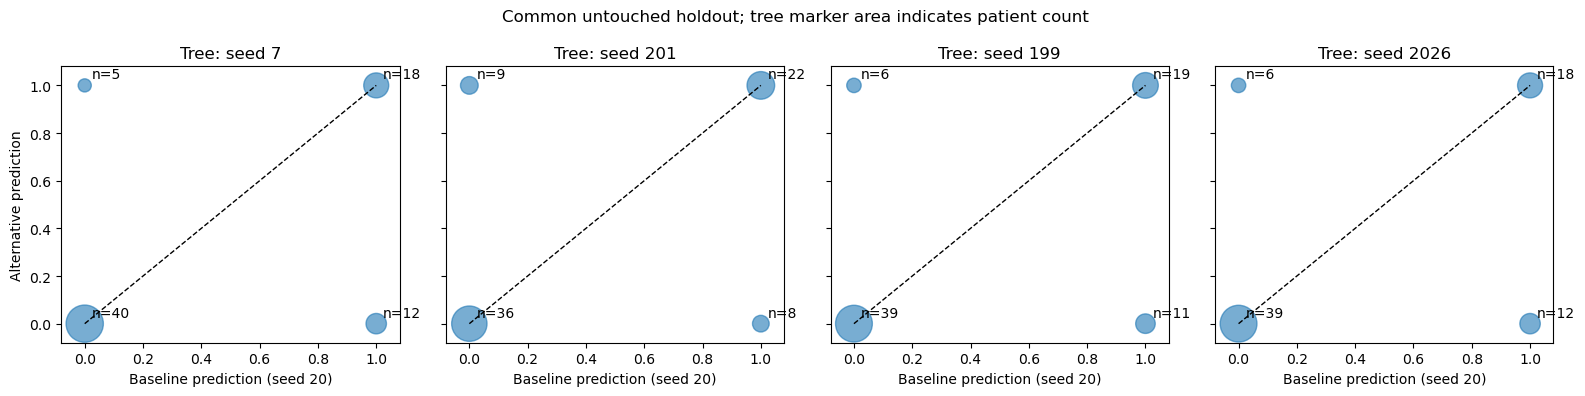

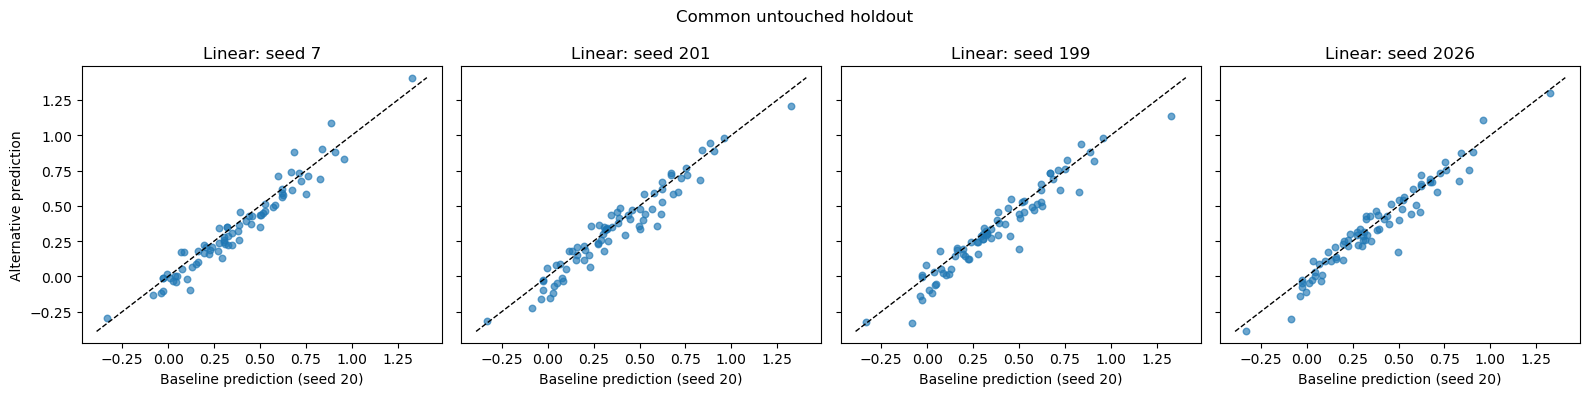

,model,seed,correlation,intercept,slope,comparison_R2,mean_absolute_difference
0,Tree,7,0.5194,0.1111,0.4889,0.2698,0.2267
1,Tree,201,0.5306,0.2000,0.5333,0.2815,0.2267
2,Tree,199,0.5196,0.1333,0.5000,0.2700,0.2267
3,Tree,2026,0.4901,0.1333,0.4667,0.2402,0.2400
4,Linear,7,0.9716,-0.0414,1.0253,0.9440,0.0656
5,Linear,201,0.9659,-0.0293,0.9947,0.9330,0.0665
6,Linear,199,0.9654,-0.0405,1.0015,0.9320,0.0668
7,Linear,2026,0.9685,-0.0276,1.0199,0.9379,0.0602


Comparison R² measures similarity between predictions, not accuracy against outcomes.
For these fully grown trees, absolute difference is also the fraction of disagreements.
All holdout-separation, row-alignment, coefficient-conversion, and R² checks passed.


In [3]:
# Q4a: separate panels preserve visibility for each alternative seed.
for name, table in predictions.items():
    fig, axes = plt.subplots(1, len(ALTERNATIVES), figsize=(16, 4), sharex=True, sharey=True)
    low = min(0, table.to_numpy().min())
    high = max(1, table.to_numpy().max())
    for ax, seed in zip(axes, ALTERNATIVES):
        if name == "Tree":
            counts = table.groupby([BASE, seed]).size().reset_index(name="count")
            ax.scatter(counts[BASE], counts[seed], s=counts["count"] * 18, alpha=0.6)
            for _, row in counts.iterrows():
                ax.annotate(f"n={int(row['count'])}", (row[BASE], row[seed]),
                            xytext=(5, 5), textcoords="offset points")
        else:
            ax.scatter(table[BASE], table[seed], alpha=0.65, s=22)
        ax.plot([low, high], [low, high], "k--", linewidth=1)
        ax.set_title(f"{name}: seed {seed}")
        ax.set_xlabel("Baseline prediction (seed 20)")
        ax.set_xlim(low - 0.08, high + 0.08)
        ax.set_ylim(low - 0.08, high + 0.08)
    axes[0].set_ylabel("Alternative prediction")
    fig.suptitle("Common untouched holdout; tree marker area indicates patient count"
                 if name == "Tree" else "Common untouched holdout")
    plt.tight_layout()
    plt.show()

# Q4b–c and Q5: alternative predictions regressed on baseline predictions.
comparison_rows = []
for name, table in predictions.items():
    assert table.index.equals(pd.Index(holdout_ids))
    baseline = table[BASE].to_numpy()
    for seed in ALTERNATIVES:
        alternative = table[seed].to_numpy()
        regression = LinearRegression().fit(baseline[:, None], alternative)
        correlation = np.corrcoef(baseline, alternative)[0, 1]
        comparison_r2 = regression.score(baseline[:, None], alternative)
        np.testing.assert_allclose(comparison_r2, correlation ** 2, atol=1e-12)
        comparison_rows.append({
            "model": name, "seed": seed, "correlation": correlation,
            "intercept": regression.intercept_, "slope": regression.coef_[0],
            "comparison_R2": comparison_r2,
            "mean_absolute_difference": np.mean(np.abs(baseline - alternative))
        })
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))
print("Comparison R² measures similarity between predictions, not accuracy against outcomes.")
print("For these fully grown trees, absolute difference is also the fraction of disagreements.")
assert np.isin(predictions["Tree"].to_numpy(), [0, 1]).all()
print("All holdout-separation, row-alignment, coefficient-conversion, and R² checks passed.")

In [4]:
# Data-driven answers to Q4–6, using the executed revised analysis.
paragraphs = []
for name in ["Tree", "Linear"]:
    rows = comparison.query("model == @name")
    ranges = {column: f"{rows[column].min():.3f} to {rows[column].max():.3f}"
              for column in ["correlation", "intercept", "slope", "comparison_R2"]}
    paragraphs.append(
        f"**{name}, Q4:** Correlations range from {ranges['correlation']}; "
        f"intercepts from {ranges['intercept']}; slopes from {ranges['slope']}; "
        f"and comparison R² from {ranges['comparison_R2']}. "
        f"The mean absolute prediction difference, averaged over four alternatives, is "
        f"{rows['mean_absolute_difference'].mean():.3f}."
    )
display(Markdown("\n\n".join(paragraphs)))
print("Raw coefficient ranges for interpretation:")
display(coefficient_summary.loc[["age", "ejection_fraction", "time"], ["minimum", "maximum", "std"]])
print("Common-holdout predictive performance by model:")
display(performance.query("evaluation == 'Common holdout'").groupby("model")[["RMSE", "R2"]].agg(["min", "max"]).round(4))

**Tree, Q4:** Correlations range from 0.490 to 0.531; intercepts from 0.111 to 0.200; slopes from 0.467 to 0.533; and comparison R² from 0.240 to 0.282. The mean absolute prediction difference, averaged over four alternatives, is 0.230.

**Linear, Q4:** Correlations range from 0.965 to 0.972; intercepts from -0.041 to -0.028; slopes from 0.995 to 1.025; and comparison R² from 0.932 to 0.944. The mean absolute prediction difference, averaged over four alternatives, is 0.065.

Raw coefficient ranges for interpretation:


,minimum,maximum,std
age,0.003853,0.007981,0.001531
ejection_fraction,-0.013710,-0.008197,0.002132
time,-0.002984,-0.002750,0.000090


Common-holdout predictive performance by model:


RMSE              R2        
           min     max     min     max
model                                 
Linear  0.3718  0.3942  0.2860  0.3647
Tree    0.4899  0.5774 -0.5319 -0.1029

#### Answers to Questions 3–6

**Q3:** The tree rules, root thresholds, depths, and leaf counts differ across seeds, as shown above. The linear coefficients vary too, but their prominent directions remain consistent: age is positive, while ejection fraction and follow-up time are negative in all five fits. In original units, the time coefficient ranges from approximately −0.00298 to −0.00275 per day. Age varies from 0.00385 to 0.00798 per year, so it is less stable proportionally. Smaller coefficients should not be interpreted as robust effects merely because predictions are stable. These are associations in the fitted model, not causal effects.

**Q4a:** The linear prediction scatterplots cluster near the identity line. The tree panels contain appreciable counts in the off-diagonal (0, 1) and (1, 0) positions, showing disagreements. Counts and marker areas reveal patients hidden by overlapping binary predictions.

**Q4b–c:** Linear correlations are 0.965–0.972, intercepts −0.041 to −0.028, slopes 0.995–1.025, and comparison R² values 0.932–0.944. These are reasonably close to the identity relationship. Tree correlations are only 0.490–0.531, intercepts 0.111–0.200, slopes 0.467–0.533, and comparison R² values 0.240–0.282. Tree slopes and R² values are far from 1, so their predictions are considerably less similar.

**Q5:** The linear fits have consistent directions for several prominent coefficients and very similar predictions, though individual coefficients are not equally stable. Their average absolute prediction difference is about 0.065. The unpruned trees change structure and disagree with the baseline on about 23% of common-holdout patients on average. Thus the linear model is more stable under these changes in training data.

**Q6:** **False as a general description of both model types in this experiment.** The statement is supported for the linear predictions, but not for the unpruned trees: structural variation accompanies meaningful prediction disagreement. This is an empirical conclusion for these seeds and model settings, not a claim about all trees. Moreover, stability does not ensure accuracy. Common-holdout R² is approximately 0.286–0.365 for the linear fits and −0.532 to −0.103 for the trees. Negative predictive R² means the tree is worse in squared error than the constant holdout-mean benchmark. Prediction-comparison R² is a different quantity and must not be confused with predictive performance.

**Verification and limits:** All Phase 2 cells ran successfully. Assertions verify that no holdout patient enters any training or internal test set, all prediction tables align on patient index, converted coefficients reproduce pipeline predictions, training sizes match, and comparison R² equals squared correlation. The dataset is small, the four alternative training samples overlap, and these summaries are descriptive rather than independent replications or uncertainty estimates. The revised analysis also changes the split design and training size relative to Phase 1, so exact metric changes cannot be attributed solely to removing overlap. Follow-up duration and the binary target limit the interpretation described above.

### *Reflection on AI assistance
In your own words without generative AI.

As a computer science student, I find AI really helpful when working on data science and machine learning projects, especially when dealing with large datasets, debugging code, and building models. I mainly use AI as a coding assistant to help me work more efficiently and understand concepts that I am unfamiliar with.

For example, when working with Python libraries like Pandas, Scikit-learn, and Matplotlib, I often use AI to help clean messy datasets, handle missing values, and generate visualizations. When training machine learning models such as Linear Regression, Random Forest, or XGBoost, I use AI to understand which models might work best for my dataset, how to tune hyperparameters, and how to interpret results like RMSE and R². I also find AI especially useful when debugging errors in Jupyter notebooks or figuring out why a model is performing poorly.

One thing I have learned is that AI-generated code does not always work correctly, so I always try to understand the logic and test the results instead of blindly copying everything.

Overall, AI has made my data science workflow much faster and helped me spend more time analyzing results and understanding what the data actually tells us.